# Borderline claims: percolation clustering and FAQ

**1. Percolation: does clustered beat top degree?**
- **Round 1:** clustered beat top degree on PAPER (+0.14 mean success over the grid). On ER it was borderline (+0.12, interval crossing zero), and in a later check on 20 fresh ER pairs it did not hold up (fewer queries on 6 pairs, more on 4).
- **Here:** 50 fresh pairs per model (pair indices 100–149, never used before), top degree against clustered, with round 1's settings and budgets. About 5 minutes.

**2. FAQ: is degree all that matters?**
- **Round 1:** with 10 pairs, no rule beat top degree, spread did worse, and distinguishing looked better on Chung–Lu.
- **Here:** round 1's FAQ run is extended to 20 pairs with all five rules, using round 1's own runner. This takes about 35–40 minutes. The main notebook (`rule_comparison.ipynb`) picks up the new pairs too.

**How to read the results** (written before the runs)
- **Percolation:** the claim holds on a model if clustered needs fewer queries than top degree on clearly more fresh pairs than the reverse (sign test p < 0.05).
- **FAQ:** "degree is all that matters" holds if no rule beats top degree clearly, while rules that move away from high degree (random, spread) do worse.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
if str(EXPERIMENT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR.parent))

from selection_rule_comparison.archive import borderline_check as BC

RUN_PERCOLATION = True   # False: only analyse saved results
RUN_FAQ = True
COLORS = {'random': '#9E9E9E', 'top_degree': '#222222', 'clustered': '#1F77B4', 'spread': '#D62728',
          'distinguishing': '#2CA02C'}
RULE_ORDER = ['top_degree', 'clustered', 'distinguishing', 'spread', 'random']

## Run

Percolation runs first (about 5 minutes), then FAQ (about 35–40 minutes). FAQ's progress goes to `logs/main_faq_*.log`, as in round 1. Rerunning skips finished pairs. From a terminal: `python -m selection_rule_comparison.borderline_check`.

In [2]:
if RUN_PERCOLATION:
    BC.run_percolation(jobs=3)
if RUN_FAQ:
    BC.run_faq(jobs=3)

01:22:30 percolation: 100 fresh pairs to run, 3 at a time.
01:23:27 [10/100] ER pair 109: 12 runs in 14 s
01:24:05 [20/100] ER pair 119: 12 runs in 12 s
01:25:05 [30/100] ER pair 129: 12 runs in 19 s
01:26:08 [40/100] ER pair 139: 12 runs in 14 s
01:26:48 [50/100] ER pair 149: 12 runs in 14 s
01:27:35 [60/100] PAPER pair 109: 12 runs in 14 s
01:28:23 [70/100] PAPER pair 120: 12 runs in 13 s
01:29:04 [80/100] PAPER pair 129: 12 runs in 14 s
01:29:58 [90/100] PAPER pair 139: 12 runs in 15 s
01:30:56 [100/100] PAPER pair 149: 12 runs in 19 s
01:30:58 Percolation done. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/borderline/percolation
2026-10-27T01:30:59-04:00  faq: running 3 graph models in parallel. Progress logs:
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/main_faq_sparse_er.log
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/main_faq_paper_pa.log
    tai

python(62373) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(62374) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(62375) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(62376) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


2026-10-27T02:46:46-04:00  faq/chung_lu finished in 75.4 min
2026-10-27T02:48:54-04:00  faq/paper_pa finished in 77.6 min
2026-10-27T02:55:45-04:00  faq/sparse_er finished in 84.3 min
2026-10-27T02:55:46-04:00  all requested runs are complete.


## 1. Percolation on fresh pairs

**Plot:** the success rate of top degree and clustered on the 50 fresh pairs per model.

**Table:** clustered against top degree, pair by pair.
- **Fewer / same / more:** pairs where clustered needs fewer, the same or more queries than top degree.
- **p:** a sign test of fewer against more.
- **Mean change:** clustered minus top degree in queries needed, with a 95% bootstrap interval. Negative means clustered needs fewer.
- **Pairs:** the "round 1 + fresh" rows pool the 20 round-1 pairs with the fresh ones, as a secondary view.

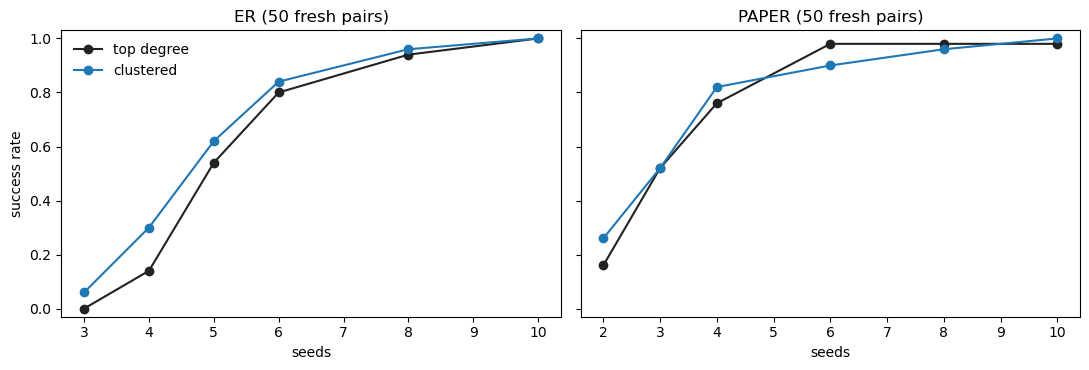

mean queries: top degree  mean queries: clustered  \
model pairs used                                                           
ER    fresh                               5.580                    5.280   
      round 1 + fresh                     5.571                    5.071   
PAPER fresh                               3.720                    3.340   
      round 1 + fresh                     3.900                    3.371   

                       pairs  fewer  same  more      p           mean change  
model pairs used                                                              
ER    fresh               50     21    15    14  0.311  -0.30 [-0.82, +0.22]  
      round 1 + fresh     70     32    20    18  0.065  -0.50 [-0.96, -0.04]  
PAPER fresh               50     17    23    10  0.248  -0.38 [-0.78, +0.02]  
      round 1 + fresh     70     27    31    12  0.024  -0.53 [-0.87, -0.17]

In [3]:
percolation = BC.load_percolation(include_round1=True)
fresh = percolation[percolation['source'] == 'fresh']
models = [m for m in BC.PERCOLATION_MODELS if m in set(fresh['model'])]

fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 3.8), sharey=True, squeeze=False)
for ax, model in zip(axes[0], models):
    data = fresh[fresh['model'] == model]
    for rule in BC.PERCOLATION_RULES:
        curve = data[data['rule'] == rule].groupby('budget')['success'].mean()
        ax.plot(curve.index, curve.values, marker='o', color=COLORS[rule], label=BC.LABELS[rule])
    ax.set_title(f"{BC.MODEL_LABELS[model]} ({data['pair_index'].nunique()} fresh pairs)")
    ax.set_xlabel('seeds')
    ax.set_ylim(-0.03, 1.03)
axes[0, 0].set_ylabel('success rate')
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

rows = []
for model in models:
    for label, part in [('fresh', fresh), ('round 1 + fresh', percolation)]:
        q = BC.queries_needed(part[part['model'] == model].assign(
            pair_index=lambda d: d['source'] + '_' + d['pair_index'].astype(str)))
        means = q.groupby('rule')['queries'].mean()
        rows.append({'model': BC.MODEL_LABELS[model], 'pairs used': label,
                     'mean queries: top degree': means['top_degree'], 'mean queries: clustered': means['clustered'],
                     **BC.compare(q, 'clustered', 'top_degree')})
display(pd.DataFrame(rows).set_index(['model', 'pairs used']).round(3))

## 2. FAQ with 20 pairs

**Plot:** success curves of all five round-1 rules.

**Table:** each rule against top degree, pair by pair, with the same columns as above. Negative mean change means the rule needs fewer queries than top degree.

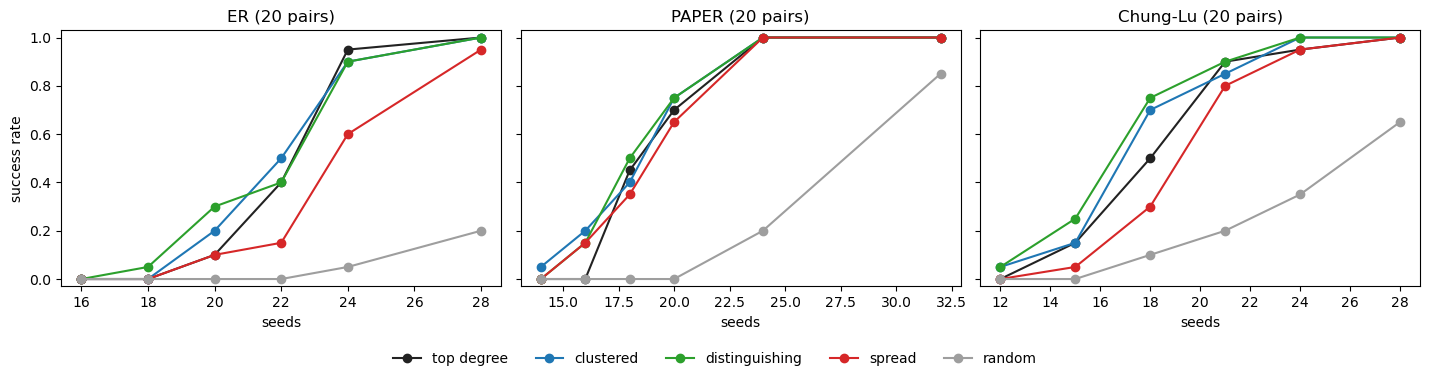

mean queries: rule  mean queries: top degree  pairs  \
model    rule                                                                  
ER       clustered                    23.00                     23.20     20   
         distinguishing               22.80                     23.20     20   
         spread                       25.30                     23.20     20   
         random                       31.00                     23.20     20   
PAPER    clustered                    19.50                     20.10     20   
         distinguishing               19.70                     20.10     20   
         spread                       20.40                     20.10     20   
         random                       31.60                     20.10     20   
Chung-Lu clustered                    18.75                     19.35     20   
         distinguishing               17.85                     19.35     20   
         spread                       20.75                     19.35     20   
         random                       26.90                     19.35     20   

                         fewer  same  more      p             mean change  
model    rule                                                              
ER       clustered           7     8     5  0.774    -0.20 [-1.20, +0.80]  
         distinguishing      6    11     3  0.508    -0.40 [-1.20, +0.40]  
         spread              0    11     9  0.004    +2.10 [+1.00, +3.30]  
         random              0     0    20  0.000    +7.80 [+6.80, +8.80]  
PAPER    clustered           8     7     5  0.581    -0.60 [-1.90, +0.70]  
         distinguishing      8     8     4  0.388    -0.40 [-1.50, +0.80]  
         spread              7     8     5  0.774    +0.30 [-1.00, +1.70]  
         random              0     1    19  0.000  +11.50 [+9.10, +13.70]  
Chung-Lu clustered           6    10     4  0.754    -0.60 [-1.80, +0.45]  
         distinguishing     10     6     4  0.180    -1.50 [-2.85, -0.15]  
         spread              1     9    10  0.012    +1.40 [+0.60, +2.15]  
         random              0     3    17  0.000    +7.55 [+5.30, +9.65]

In [4]:
faq = BC.load_faq()
faq_models = [m for m in ['sparse_er', 'paper_pa', 'chung_lu'] if m in set(faq['model'])]

fig, axes = plt.subplots(1, len(faq_models), figsize=(4.8 * len(faq_models), 3.8), sharey=True, squeeze=False)
for ax, model in zip(axes[0], faq_models):
    data = faq[faq['model'] == model]
    for rule in [r for r in RULE_ORDER if r in set(data['rule'])]:
        curve = data[data['rule'] == rule].groupby('budget')['success'].mean()
        ax.plot(curve.index, curve.values, marker='o', color=COLORS[rule], label=BC.LABELS[rule])
    ax.set_title(f"{BC.MODEL_LABELS[model]} ({data['pair_index'].nunique()} pairs)")
    ax.set_xlabel('seeds')
    ax.set_ylim(-0.03, 1.03)
axes[0, 0].set_ylabel('success rate')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

rows = []
for model in faq_models:
    q = BC.queries_needed(faq[faq['model'] == model])
    means = q.groupby('rule')['queries'].mean()
    for rule in [r for r in RULE_ORDER if r in means.index and r != 'top_degree']:
        rows.append({'model': BC.MODEL_LABELS[model], 'rule': BC.LABELS[rule],
                     'mean queries: rule': means[rule], 'mean queries: top degree': means['top_degree'],
                     **BC.compare(q, rule, 'top_degree')})
display(pd.DataFrame(rows).set_index(['model', 'rule']).round(3))